# Toxic comments: historical evidence and new protocol review

## tl;dr

- The historical five-epoch transformer selects **epoch 3** by validation loss: macro ROC-AUC **0.9790**, macro F1 **0.3900** at strict score `> 0.5`. Its final-epoch F1 **0.4391** belongs to epoch 5.
- Historical threat precision is **0.048** despite recall **0.853**. High ranking scores do not establish a useful decision threshold or calibrated risk.
- Later supplied real files contain **159,571 training-source rows** and **153,164 unlabeled challenge-test rows**. The reviewed new run drops seven normalized-empty training comments and keeps conflicting annotations together.
- The completed new CPU protocol scores **23,955 exploratory internal-test rows**, with macro AP **0.6502**, macro ROC-AUC **0.9811**, macro F1 **0.6346**, and micro F1 **0.7483** at frozen validation-selected thresholds. This **different 70/15/15 grouped internal protocol** cannot establish a controlled improvement over the historical neural results. No pristine external test or full-data neural reproduction is available.

This notebook is an executable aggregate review. It does not read raw comments, train a model, download assets, or recreate the historical scores.

## Context & Methods

The original notebooks use an 80/20 random row split, repeatedly inspect validation, and choose the minimum-loss checkpoint. Only the `roberta-base` tokenizer is pretrained; the eight-layer encoder is randomly initialized. The per-label historical table uses last-epoch arrays, even though demonstration inference reloads another checkpoint.

The new reference protocol fits TF-IDF and six logistic regressions on training text only. Normalized exact-text groups stay in one partition; thresholds are selected on validation only and frozen before one internal-test evaluation. The original cohort was already examined historically. Grouping does not establish independence of paraphrases, authors, discussions, or time.

### Key Assumptions

Stored neural numbers retain their reported rounding and provenance. Later CSV bytes do not prove the identity of the historical training input. Source-level class counts below precede the seven empty-text exclusions; run supports come from the retained cohort. Unknown challenge-test labels are not negative labels. Undefined new-run metrics remain null.

Environment: Python 3.12 and `requirements-notebooks.txt`. From the project root, execute `python scripts/run_results_notebook.py`; its kernel uses the invoking interpreter. This sandbox blocks local kernel sockets, so the saved review was executed with `--engine inprocess` in a fresh IPython process; its metadata records that mode.

In [1]:
from pathlib import Path
import sys
import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import Markdown, display

project_root = next(
    candidate for candidate in (Path.cwd(), *Path.cwd().parents)
    if (candidate / "reports/historical_metrics.json").is_file()
)
sys.path.insert(0, str(project_root / "scripts"))
from render_historical_results import (
    LABELS, load_evidence, records_by_name, summary_dataframe,
    per_label_dataframe, plot_training_history, plot_per_label_report,
)
from render_real_results import (
    load_data_audit, audit_dataframe, plot_label_prevalence,
    load_run_results, run_summary_dataframe, run_per_label_dataframe,
    plot_run_per_label, tuned_metric_key,
)

from IPython.core.pylabtools import select_figure_formats
select_figure_formats(get_ipython(), {"png"})
historical = load_evidence(project_root / "reports/historical_metrics.json")
data_audit = load_data_audit(project_root / "reports/data_audit.json")
records = records_by_name(historical)
print("Loaded aggregate evidence only; no raw comments or model files.")

Loaded aggregate evidence only; no raw comments or model files.


## Data

### 1. Trace the historical inputs

The committed [historical metrics record](../reports/historical_metrics.json) identifies original file hashes, zero-based cell indexes, output indexes, and execution counts. These are saved outputs, not fresh model measurements. The two five-epoch histories match exactly and are shared evidence rather than independent replications.

In [2]:
source_table = pd.DataFrame([
    {
        "Notebook": name,
        "Recorded epochs": len(record["metrics"]),
        "Metric cell (zero-based)": record["metrics"][0]["cell_index"],
        "Original SHA-256": record["sha256"],
    }
    for name, record in records.items()
])
display(source_table)
selected = records["model_FINAL_Report.ipynb"]["best_by_validation_loss"]
assert selected["epoch"] == 3
assert records["model_FINAL_Report.ipynb"]["per_label_report"]["uses_last_epoch_prediction_arrays_from_cell_6"]

,Notebook,Recorded epochs,Metric cell (zero-based),Original SHA-256
0,Untitled10.ipynb,7,6,a090070703a768766d65ddfef4244da2af1c25fa9fc0f9...
1,modelXXXX(1).ipynb,5,6,6a6377d348a71f03fcecf37b454d7565bddf8d191184b8...
2,model_FINAL_Report.ipynb,5,6,d46c37b06c49d74f2137c23a798128a3cf1f6c21a2b054...


### 2. Inspect the later supplied source cohort

Source: [data audit](../reports/data_audit.json). These six labels overlap. Counts below use all supplied labeled-source rows, before the new run's explicit exclusions.

In [3]:
display(audit_dataframe(data_audit).style.format({"Source prevalence (%)": "{:.3f}"}))
source_checks = pd.DataFrame([
    {"Source finding": "Training-source rows", "Count": data_audit["train"]["rows"]},
    {"Source finding": "Normalized-empty training comments", "Count": data_audit["train"]["normalized_empty_text_rows"]},
    {"Source finding": "Conflicting normalized-text groups", "Count": data_audit["train"]["normalized_conflicting_label_groups"]},
    {"Source finding": "Rows in conflicting groups", "Count": data_audit["train"]["rows_in_conflicting_groups"]},
    {"Source finding": "Unlabeled challenge-test rows", "Count": data_audit["unlabeled_challenge_test"]["rows"]},
    {"Source finding": "Shared nonempty source groups", "Count": data_audit["cross_file_overlap"]["shared_nonempty_normalized_groups"]},
])
display(source_checks)
assert data_audit["unlabeled_challenge_test"]["evaluation_available"] is False
assert all(
    count == data_audit["unlabeled_challenge_test"]["rows"]
    for count in data_audit["unlabeled_challenge_test"]["blank_label_cells"].values()
)

,Label,Positive source rows,Source prevalence (%)
0,identity_hate,1405,0.880
1,insult,7877,4.936
2,obscene,8449,5.295
3,severe_toxic,1595,1.000
4,threat,478,0.300
5,toxic,15294,9.584


,Source finding,Count
0,Training-source rows,159571
1,Normalized-empty training comments,7
2,Conflicting normalized-text groups,93
3,Rows in conflicting groups,213
4,Unlabeled challenge-test rows,153164
5,Shared nonempty source groups,636


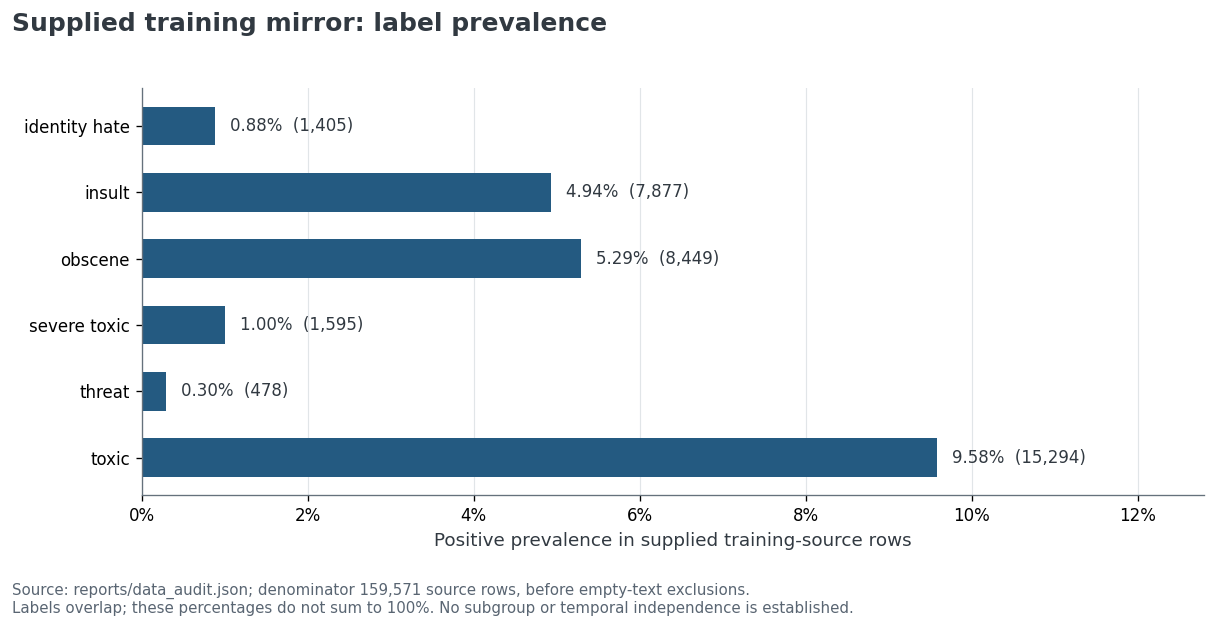

In [4]:
source_figure = plot_label_prevalence(data_audit)
display(source_figure)
plt.close(source_figure)

Threat is present in 478 source rows (about 0.30%), whereas toxic is present in 15,294 (about 9.58%). Class imbalance makes per-label supports and precision essential. The challenge-test file has blank target columns, so no score can be computed from it. Separate filenames and IDs do not undo the 636 shared normalized-text groups.

## Results

### 3. Separate selected and final historical checkpoints

F1 in these saved outputs uses strict `score > 0.5`. Table precision reflects the original four-decimal logs. Every row describes repeatedly inspected validation data.

In [5]:
historical_summary = summary_dataframe(historical)
display(historical_summary.style.format({
    "Validation loss": "{:.4f}", "Macro ROC-AUC": "{:.4f}", "Macro F1 at > 0.5": "{:.4f}",
}))

,Notebook,Recorded checkpoint,Epoch,Validation loss,Macro ROC-AUC,Macro F1 at > 0.5
0,model_FINAL_Report.ipynb,Selected by validation loss,3,0.3482,0.9790,0.3900
1,model_FINAL_Report.ipynb,Last epoch,5,0.3824,0.9792,0.4391
2,Untitled10.ipynb,Selected by validation loss,4,0.3498,0.9801,0.3818
3,Untitled10.ipynb,Last epoch,7,0.4081,0.9810,0.4459
4,modelXXXX(1).ipynb,Selected by validation loss,3,0.3482,0.9790,0.3900
5,modelXXXX(1).ipynb,Last epoch,5,0.3824,0.9792,0.4391


### 4. Review stored loss trajectories

The panels share a loss scale. Vertical guides identify selection by minimum validation loss. `modelXXXX(1).ipynb` is omitted from this plot because its stored five-epoch history is identical to FINAL_Report.

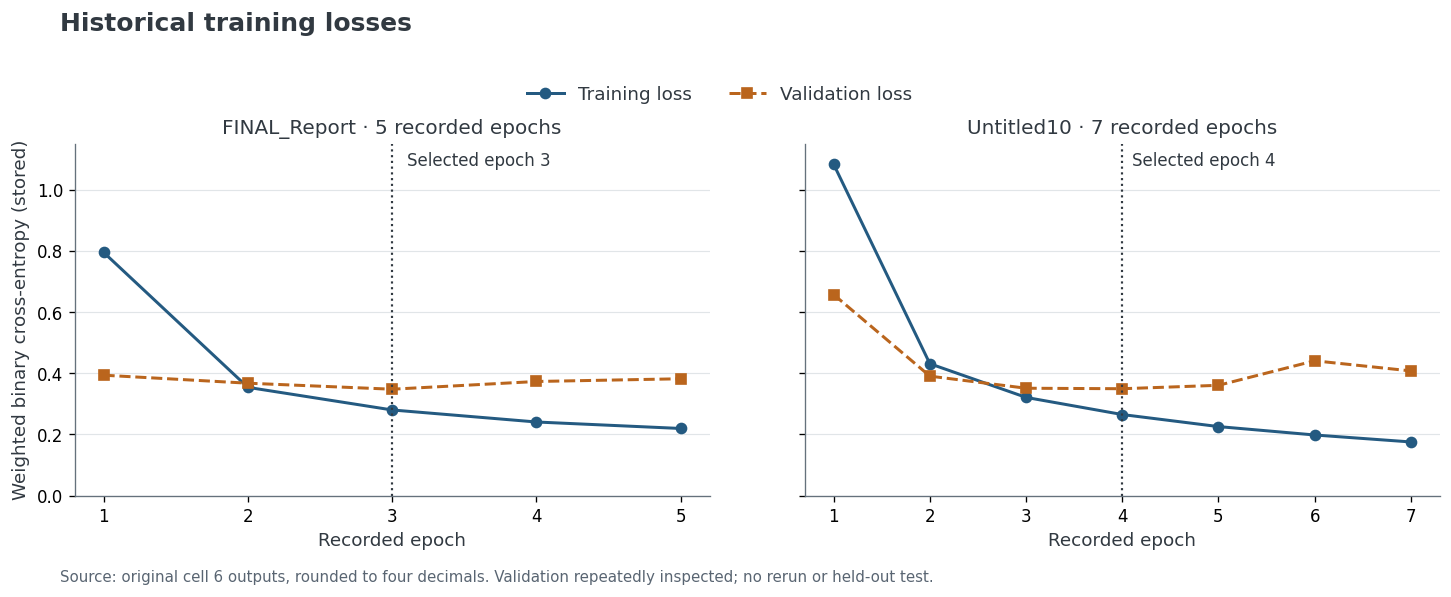

In [6]:
loss_figure = plot_training_history(historical)
display(loss_figure)
plt.close(loss_figure)

The five-epoch minimum validation loss is 0.3482 at epoch 3; its last-epoch loss is 0.3824. Untitled10 selects epoch 4 and records three subsequent non-improving losses. Different learning rate, warmup, and duration prevent attributing differences to one change. The original loss aggregation is also a mean of batch means, so these stored losses retain that historical limitation.

### 5. Review the historical operating point

The per-label output comes from FINAL_Report cell 9, whose execution count is null. Its source uses final-epoch arrays. The stored macro row is preserved rather than recalculated from rounded label values. No support counts, confidence intervals, or calibration evidence accompany this historical table.

In [7]:
display(per_label_dataframe(historical).style.format({"Precision": "{:.3f}", "Recall": "{:.3f}", "F1": "{:.3f}"}))

,Label,Precision,Recall,F1
0,identity_hate,0.124,0.911,0.218
1,insult,0.440,0.945,0.601
2,obscene,0.539,0.959,0.690
3,severe_toxic,0.203,0.975,0.336
4,threat,0.048,0.853,0.090
5,toxic,0.572,0.900,0.700
6,Macro mean (stored),0.321,0.924,0.439


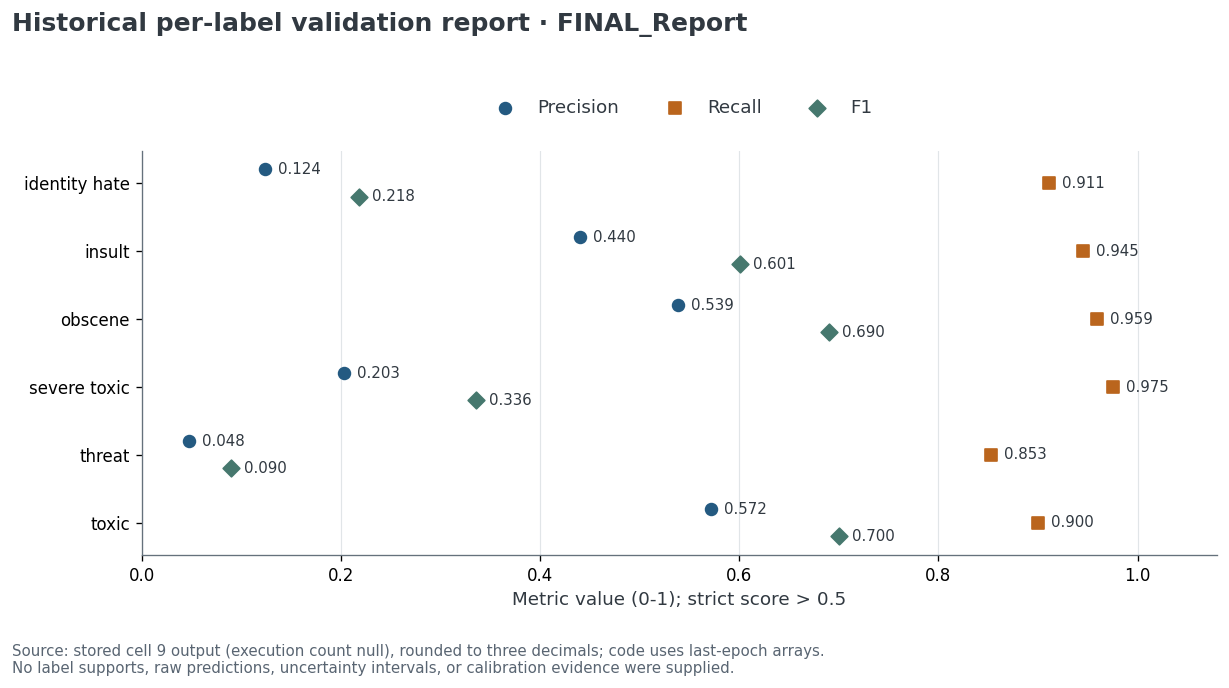

In [8]:
operating_point_figure = plot_per_label_report(historical)
display(operating_point_figure)
plt.close(operating_point_figure)

The stored macro precision is 0.321 and macro recall is 0.924. Threat and identity hate have high recall but low precision. ROC-AUC measures ranking across thresholds; it does not imply accuracy or low false-positive rates at 0.5. Macro F1 is the mean of per-label F1, not the harmonic mean of macro precision and macro recall.

### 6. Review the new CPU experiment separately

Inputs: `reports/baseline_validation_metrics.json` and `reports/baseline_internal_test_metrics.json`. All results are from the completed real-data CPU run. The cohort, partitions, model family, and threshold rule differ from the historical transformer experiment. New binary decisions use `score >= threshold`. Validation metrics are selection diagnostics. Internal-test metrics remain exploratory because this cohort was examined previously.

The primary new metric is six-label macro average precision (AP), calculated using scikit-learn's non-interpolated average precision, not trapezoidal PR area. Ranking coverage must be 6/6 to interpret the full six-label macro. The reviewed policies explicitly drop seven empty-text rows and retain conflicting annotations without label merging.

In [9]:
new_results = {}
for partition, filename in (
    ("Validation (selection diagnostics)", "baseline_validation_metrics.json"),
    ("Exploratory internal test", "baseline_internal_test_metrics.json"),
):
    source_path = project_root / "reports" / filename
    if not source_path.is_file():
        raise FileNotFoundError(source_path)
    if source_path.is_file():
        new_results[partition] = load_run_results(source_path)
        display(Markdown(f"**{partition}** - source: `{filename}`"))
        display(run_summary_dataframe(new_results[partition]).style.format({
            "Macro AP": "{:.4f}", "Macro ROC-AUC": "{:.4f}", "Macro F1": "{:.4f}", "Micro F1": "{:.4f}",
        }, na_rep="undefined"))
    else:
        display(Markdown(f"**{partition}:** aggregate results have not yet been committed."))

**Validation (selection diagnostics)** - source: `baseline_validation_metrics.json`

,Threshold policy,Rows,Macro AP,Macro ROC-AUC,Macro F1,Micro F1,Ranking labels
0,Fixed 0.5,23878,0.6549,0.9823,0.6087,0.7257,6/6
1,Validation-selected,23878,0.6549,0.9823,0.6414,0.7546,6/6


**Exploratory internal test** - source: `baseline_internal_test_metrics.json`

,Threshold policy,Rows,Macro AP,Macro ROC-AUC,Macro F1,Micro F1,Ranking labels
0,Fixed 0.5,23955,0.6502,0.9811,0.6144,0.7330,6/6
1,Validation-selected,23955,0.6502,0.9811,0.6346,0.7483,6/6


### 7. Inspect new internal-test label supports and metrics

Null values retain their undefined meaning. Selected thresholds come only from validation and are frozen before this evaluation. The table and chart are aggregate-only and do not reveal comments or individual decisions.

In [10]:
internal_results = new_results.get("Exploratory internal test")
if internal_results is not None:
    display(run_per_label_dataframe(internal_results).style.format({
        "Threshold": "{:.2f}", "AP": "{:.4f}", "ROC-AUC": "{:.4f}",
        "Precision": "{:.4f}", "Recall": "{:.4f}", "F1": "{:.4f}",
    }, na_rep="undefined"))
else:
    display(Markdown("No committed internal-test aggregate is available to review yet."))

,Label,Positive support,Threshold,AP,ROC-AUC,Precision,Recall,F1
0,identity_hate,224,0.70,0.4887,0.9704,0.4206,0.6027,0.4954
1,insult,1196,0.60,0.7868,0.9791,0.6655,0.8002,0.7267
2,obscene,1290,0.70,0.8928,0.9879,0.8241,0.8209,0.8225
3,severe_toxic,261,0.80,0.4611,0.9875,0.4329,0.6054,0.5048
4,threat,67,0.85,0.3884,0.9856,0.4400,0.4925,0.4648
5,toxic,2299,0.75,0.8833,0.9763,0.8383,0.7529,0.7933


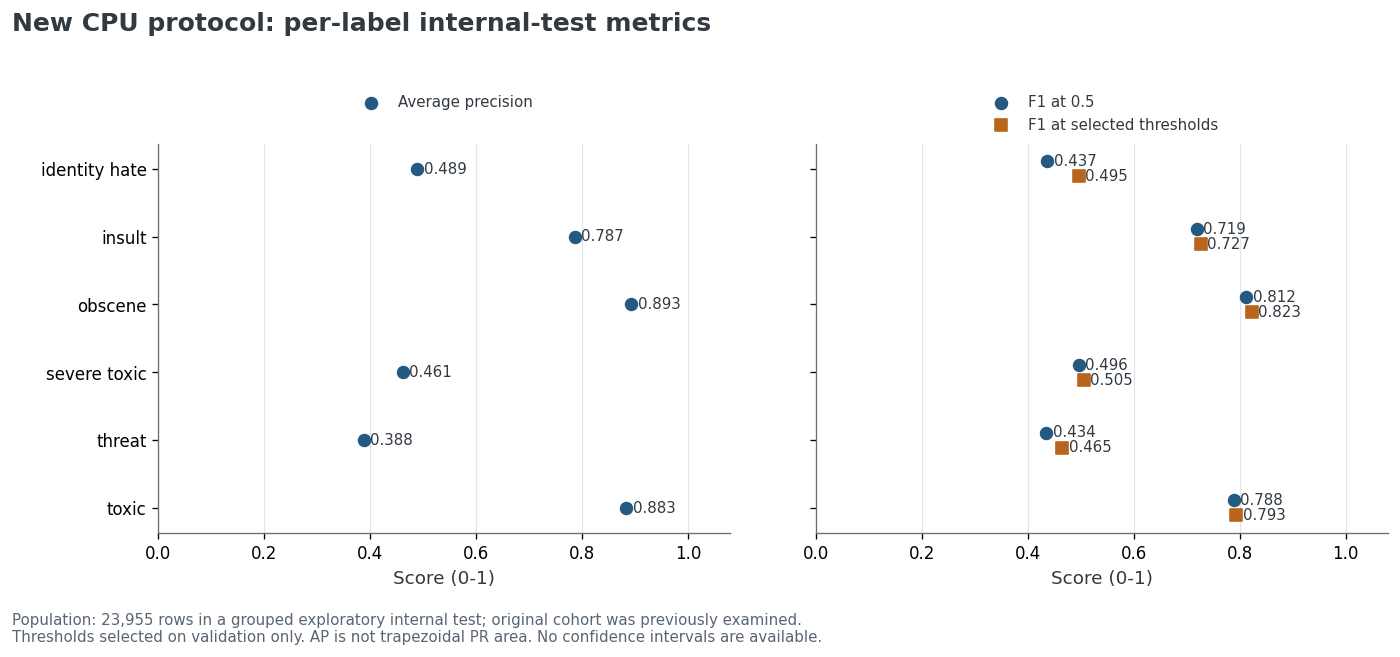

The new CPU protocol scores **23,955 internal-test rows**, with ranking coverage **6/6**. The threshold comparison reuses this model's scores; it is not a neural-versus-baseline comparison. No confidence interval or untouched external cohort is supplied.

In [11]:
if internal_results is not None:
    internal_figure = plot_run_per_label(internal_results)
    display(internal_figure)
    plt.close(internal_figure)
    metrics = internal_results[tuned_metric_key(internal_results)]
    display(Markdown(
        f"The new CPU protocol scores **{metrics['rows']:,} internal-test rows**, "
        f"with ranking coverage **{metrics['coverage']['ranking_eligible_count']}/6**. "
        "The threshold comparison reuses this model's scores; it is not a neural-versus-baseline comparison. "
        "No confidence interval or untouched external cohort is supplied."
    ))

## Takeaways

1. Preserve checkpoint identity: loss-best, last-epoch, highest F1, and highest ROC-AUC are distinct historical observations.
2. Judge each operating point using per-label precision, recall, supports, and threshold metadata. High ROC-AUC alone does not establish moderation utility.
3. Keep historical neural numbers, real source findings, synthetic mechanics checks, and new CPU metrics separate. A changed protocol does not measure a controlled improvement.
4. A new model comparison needs the same frozen source and partitions. Stronger generalization claims also need an independent cohort; repeated validation inspection and historical cohort exposure remain limitations.

[Methodology](../docs/methodology.md), [model card](../docs/model_card.md), [corrected report](../reports/corrected_report.md), [source provenance](../docs/provenance.md), and [claim corrections](../docs/report_corrections.md) provide the audit context. No fairness, explanation, calibration, latency, or deployment-readiness claim is established.